In [4]:
# Cell 1: Import libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
print("Libraries imported successfully.")

# Google Colab file upload
from google.colab import files

Libraries imported successfully.


In [5]:
# Cell 2: Upload and load dataset
df = pd.read_csv("/content/Crop_recommendation.csv")
print("Dataset loaded successfully")
df.head()

Dataset loaded successfully


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:
# Cell 3: Inspect data
print("Columns:", df.columns.tolist())
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDescriptive statistics:")
display(df.describe().T)
print("\nCrop counts:")
display(df["label"].value_counts().to_frame("Count"))

Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Missing values:


,Missing values
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117



Crop counts:


,Count
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


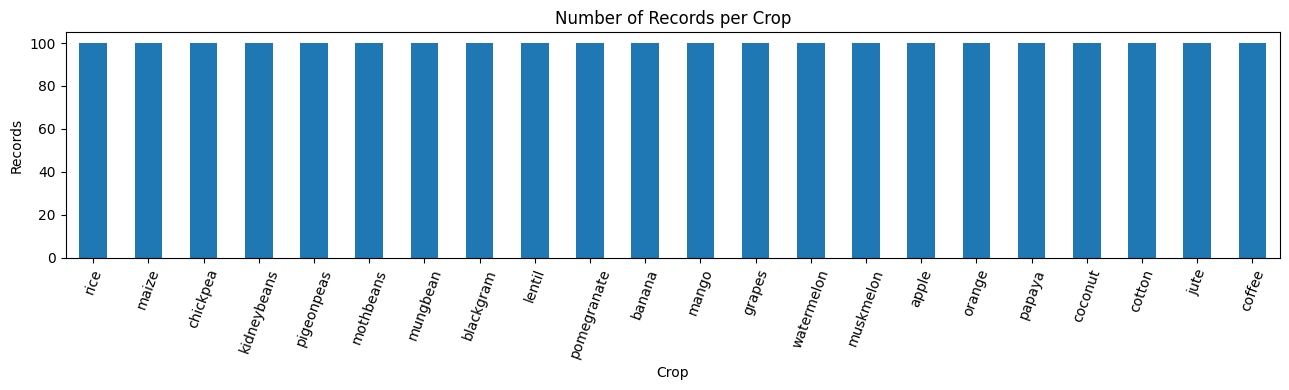

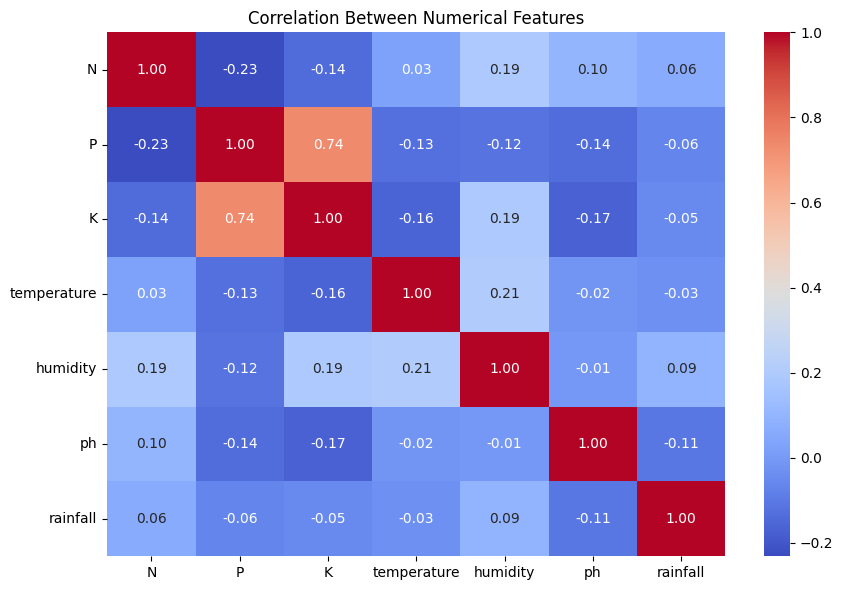

In [7]:
# Cell 4: Exploratory data analysis
df["label"].value_counts().plot(kind="bar", figsize=(13, 4))
plt.title("Number of Records per Crop")
plt.xlabel("Crop")
plt.ylabel("Records")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [8]:
# Cell 5: Clean and prepare data
df = df.drop_duplicates().reset_index(drop=True)

required_features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
missing_required = [c for c in required_features + ["label"] if c not in df.columns]
if missing_required:
    raise ValueError(f"Dataset is missing required columns: {missing_required}")

X = df[required_features].apply(pd.to_numeric, errors="coerce")
y = df["label"].astype(str)

# Remove rows without a label; numeric missing values are handled in model pipelines.
valid = y.notna() & (y.str.strip() != "")
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

print("Prepared shape:", X.shape)
print("Classes:", y.nunique())
display(X.head())

Prepared shape: (2200, 7)
Classes: 22


,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340


In [9]:
# Cell 6: Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1760
Testing records: 440


In [10]:
# Cell 7: Train and compare models
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

results = []
trained_models = {}
test_predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model
    test_predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1_macro", ascending=False).reset_index(drop=True)
display(results_df)

Training Logistic Regression...
Training Decision Tree...
Training KNN...
Training SVM...


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,SVM,0.984091,0.985610,0.984091,0.984038
1,Decision Tree,0.979545,0.980598,0.979545,0.979423
2,KNN,0.979545,0.980356,0.979545,0.979283
3,Logistic Regression,0.972727,0.974022,0.972727,0.972464


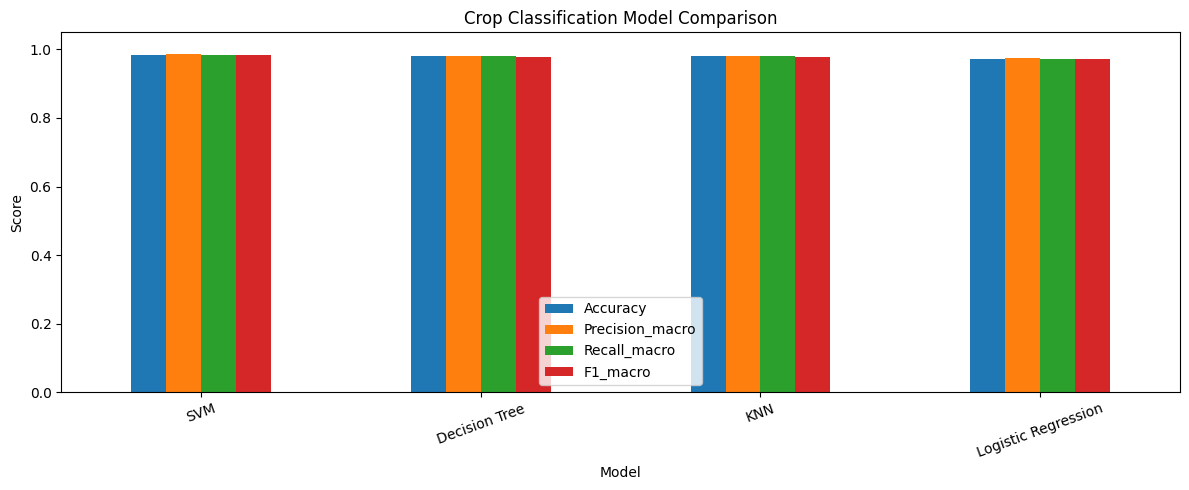

In [11]:
# Cell 8: Plot model comparison
results_df.set_index("Model")[["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]].plot(
    kind="bar", figsize=(12, 5)
)
plt.title("Crop Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [12]:
# Cell 9: Evaluate the selected model
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_pred = test_predictions[best_name]

print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, zero_division=0))

Selected model: SVM

Classification report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      0.90      0.95        20
       mango       0.95      1.00      0.98        20
   mothbeans       1.00      0.95      0.97        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00    

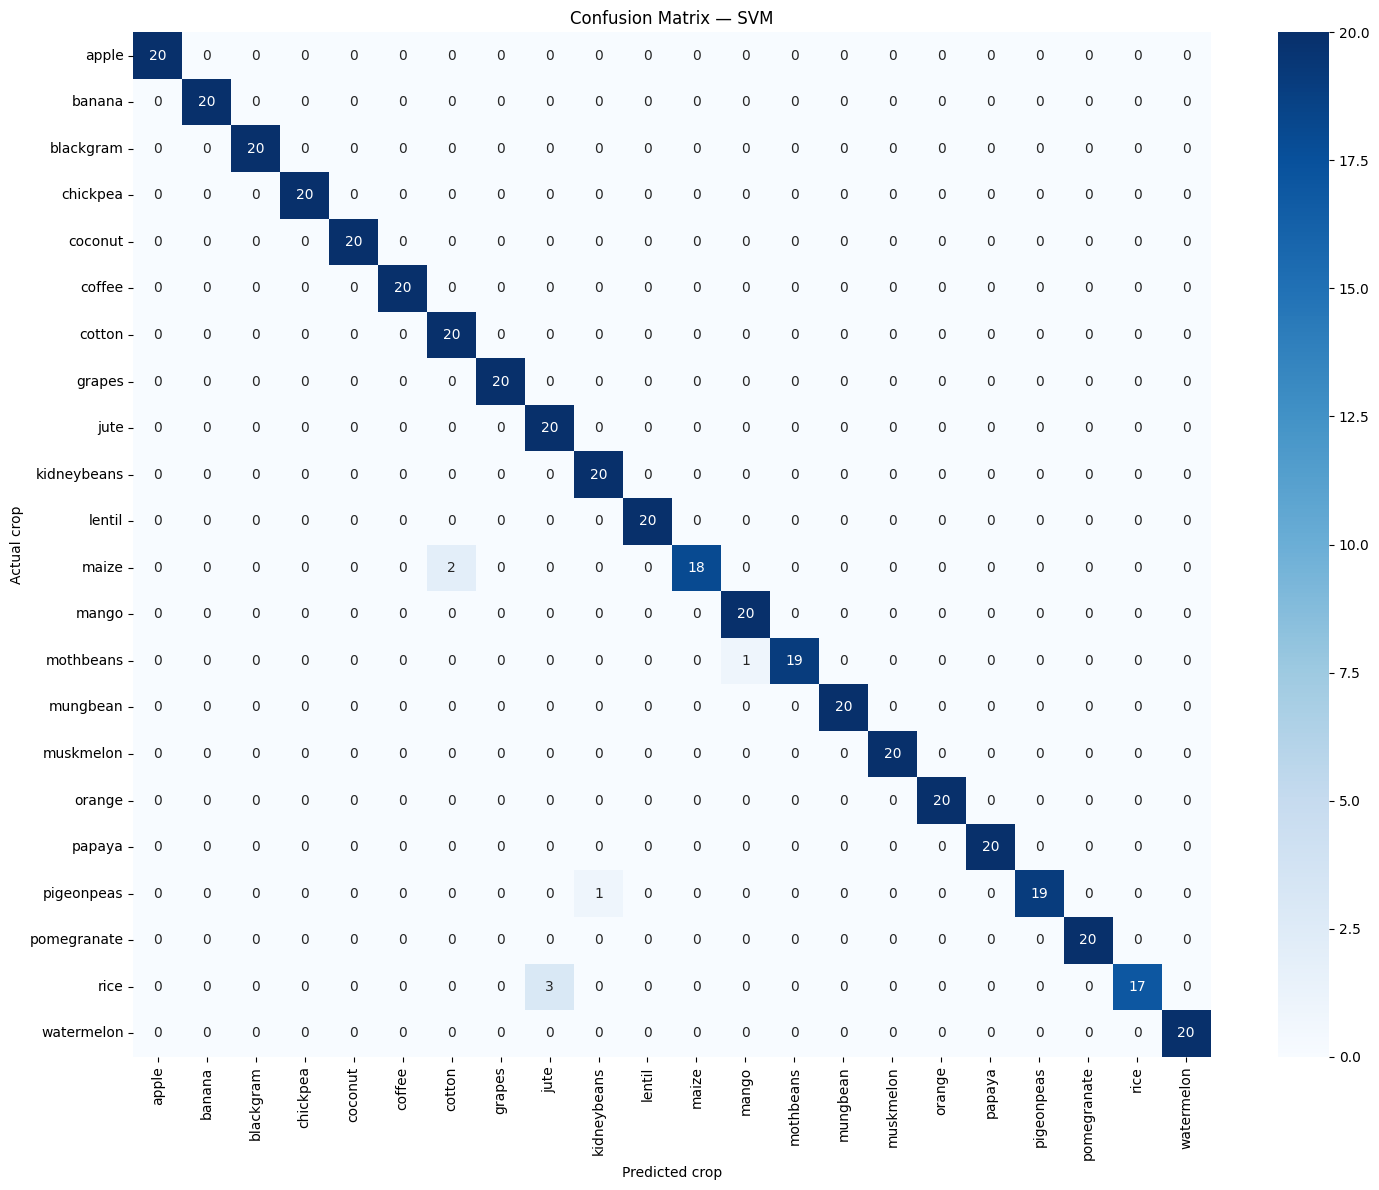

In [13]:
# Cell 10: Confusion matrix
labels = sorted(y.unique())
cm = confusion_matrix(y_test, best_pred, labels=labels)

plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted crop")
plt.ylabel("Actual crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# Cell 11: Save the model
model_package = {
    "model": best_model,
    "features": required_features,
    "classes": sorted(y.unique()),
    "best_model_name": best_name
}
joblib.dump(model_package, "crop_recommendation_model.pkl")
print("Saved crop_recommendation_model.pkl")

Saved crop_recommendation_model.pkl


In [15]:
# Cell 12: Crop recommendation function
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    input_data = pd.DataFrame([{
        "N": N,
        "P": P,
        "K": K,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall
    }], columns=required_features)

    prediction = best_model.predict(input_data)[0]
    print("Recommended crop:", prediction)

    if hasattr(best_model, "predict_proba"):
        probabilities = best_model.predict_proba(input_data)[0]
        print(f"Model confidence: {probabilities.max() * 100:.2f}%")

    return prediction

# Example input for demonstration
recommend_crop(
    N=90, P=42, K=43,
    temperature=25, humidity=80, ph=6.5, rainfall=200
)

Recommended crop: jute


'jute'